# Real-space overlap is not enough: ambiguity in nanobeam iterative ptychography

**Scan 23: Optimization workflow & direct reconstruction**

**Authors:** Stephanie M. Ribet, Mohsen Danaie, Willem P.M. de Kleijne, Arthur R. C. McCray, Frederick Allars, Christopher S. Allen, Colin Ophus, Georgios Varnavides

**Affiliations:**
- National Center for Electron Microscopy, Molecular Foundry, Lawrence Berkeley National Laboratory
- Electron Physical Sciences Imaging Centre, Diamond Light Source
- Department of Imaging Physics, Delft University of Technology
- Department of Materials Science and Engineering, Stanford University

In [1]:
%load_ext autoreload 
%autoreload 2

In [2]:
import numpy as np

import quantem as em
from quantem.core import config
from quantem.core.visualization import show_2d
import matplotlib.pyplot as plt
config.set_device(0)
print(config.get("device"))

/home/sribet/micromamba/envs/quantem/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda:0


# load data

In [3]:
probe_semiangle = 24
energy = 300e3

In [4]:
dirpath = ""
filepath_data = dirpath + "nanobeam_ptycho_23_master.h5"
dc = em.io.read_4dstem(filepath_data, file_type="arina")
print(dc)

quantem Dataset named '4D-STEM dataset'
  shape: (512, 512, 192, 192)
  dtype: uint16
  device: cpu
  origin: [0. 0. 0. 0.]
  sampling: [0.47470101 0.47470101 1.         1.        ]
  units: ['A', 'A', 'pixels', 'pixels']
  signal units: 'arb. units'


In [5]:
dc.bin(2, axes= (2,3), modify_in_place=True)

In [6]:
im =  dc.array.sum((-1,-2))

(<Figure size 400x400 with 1 Axes>, <Axes: >)

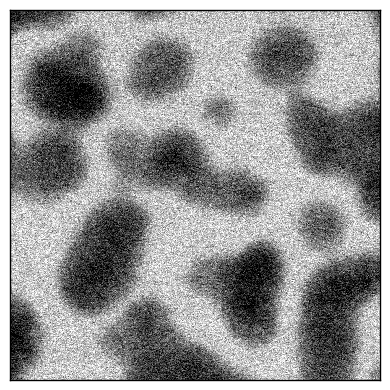

In [7]:
show_2d(
   im
)

# calibrate

In [8]:
dc.get_dp_mean()

Dataset(shape=(96, 96), dtype=float64, name='4D-STEM dataset_dp_mean')
  sampling: [2. 2.]
  units: ['pixels', 'pixels']
  signal units: 'arb. units'

(<Figure size 1200x400 with 3 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >], dtype=object))

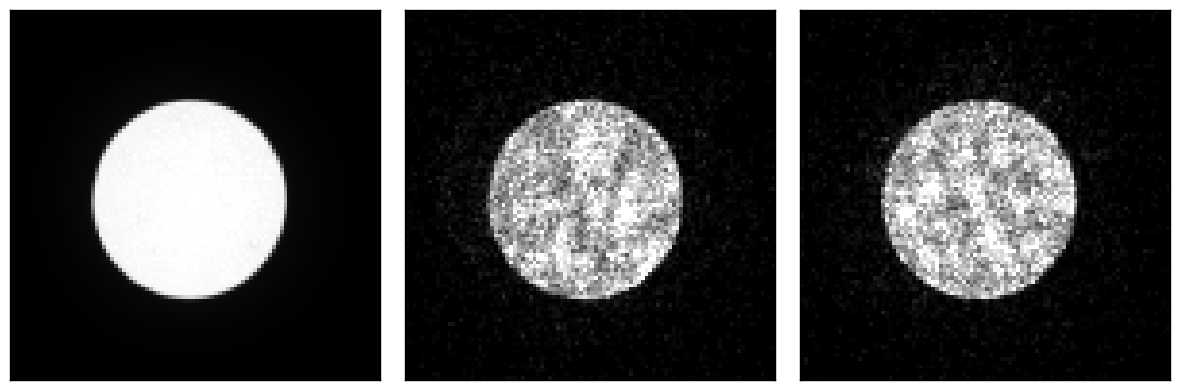

In [10]:
em.visualization.show_2d(
    [
        dc.dp_mean,
        dc.array[128,128],
        dc.array[256,256]
    ]
)

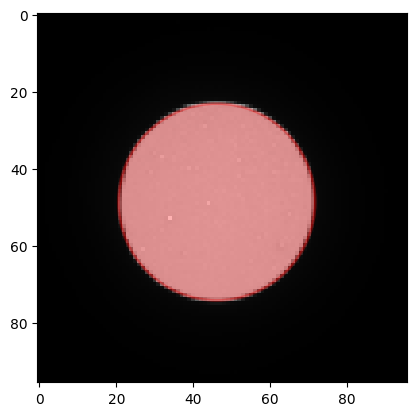

quantem Dataset named '4D-STEM dataset'
  shape: (512, 512, 96, 96)
  dtype: uint64
  device: cpu
  origin: [0.  0.  0.5 0.5]
  sampling: [0.47470101 0.47470101 0.93839721 0.93839721]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'


In [11]:
from quantem.core.utils.diffractive_imaging_utils import fit_probe_circle
probe_qy0, probe_qx0, probe_R = fit_probe_circle(dc.dp_mean.array, show=True)
dc.sampling[2] = probe_semiangle / probe_R
dc.sampling[3] = probe_semiangle / probe_R
dc.units[2:] = ["mrad", "mrad"]



print(dc)

# direct ptycho

In [12]:
import gc
import torch 

torch.cuda.empty_cache()
gc.collect()

3063

In [13]:
direct_ptycho = em.diffractive_imaging.direct_ptychography.DirectPtychography.from_dataset4d(
    dc,
    energy=energy,
    semiangle_cutoff=probe_semiangle,
    aberration_coefs={

    },
    device="gpu",
    rotation_angle=np.deg2rad(-169), 
    max_batch_size=32
)

In [14]:
from quantem.diffractive_imaging.direct_ptychography import OptimizationParameter
direct_ptycho.optimize_hyperparameters(
    aberration_coefs={
        "C10":OptimizationParameter(-400,400),
        "C12":OptimizationParameter(0, 50),
        "phi12":OptimizationParameter(-np.pi/2, np.pi/2)
    },
    deconvolution_kernel='parallax',
)

Best trial: 37. Best value: 9.59176e-09: 100%|██| 50/50 [00:18<00:00,  2.65it/s]


Optimized state:

 HyperparameterState(
  initial_rotation_angle=np.float64(-2.949606435870417),
  optimized_aberrations={'C10': -176.7006242519572, 'C12': 0.020101488288183145, 'phi12': 1.1934761463319523},
)


Reconstructing with:

 HyperparameterState(
  current_aberrations={'C10': -176.7006242519572, 'C12': 0.020101488288183145, 'phi12': 1.1934761463319523},
  current_rotation_angle=np.float64(-2.949606435870417),
)


100%|█████████████████████████████████████| 2016/2016 [00:00<00:00, 3052.80it/s]


(<Figure size 400x400 with 1 Axes>, <Axes: >)

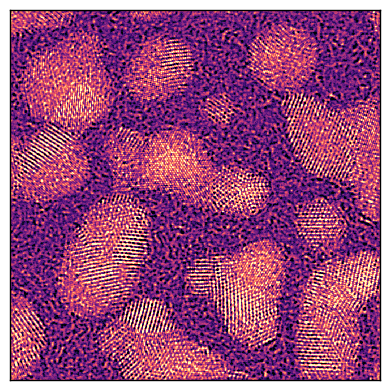

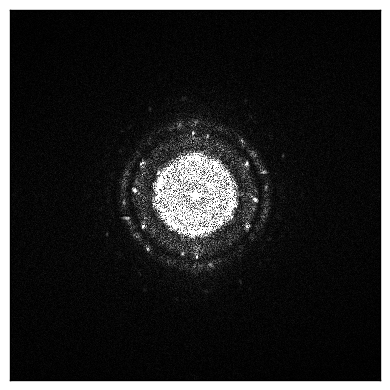

In [15]:
direct_ptycho.reconstruct(
    upsampling_factor = 2,
    deconvolution_kernel='parallax',
    max_batch_size = 10
)

show_2d(direct_ptycho.obj, cmap = "magma")


show_2d(np.fft.fftshift(np.abs(np.fft.fft2(direct_ptycho.obj))))

(<Figure size 800x800 with 1 Axes>, <Axes: >)

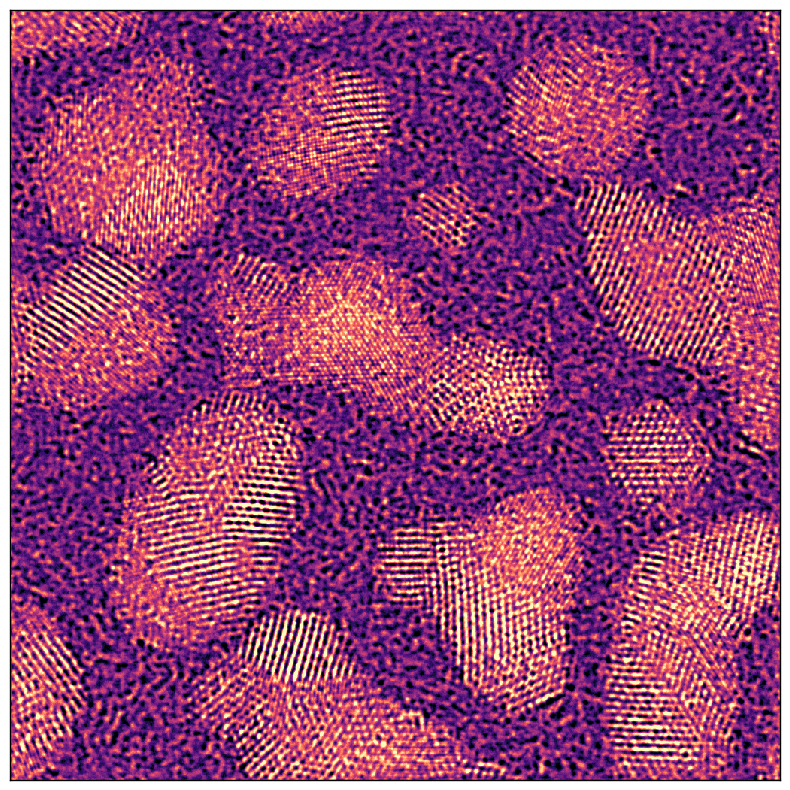

In [16]:
show_2d(
    direct_ptycho.obj, cmap = "magma",
    figsize = (8,8)
)

In [52]:
import h5py

In [54]:
with h5py.File('recons/scan_23_direct_ptycho_260522.h5', 'w') as f:
    f.create_dataset('obj', data = direct_ptycho.obj)
    f.create_dataset('sampling', data = direct_ptycho.sampling)

# iterative ptycho

In [17]:
torch.cuda.empty_cache()
gc.collect()

1622

In [18]:
from quantem.core.datastructures import Dataset4dstem
from quantem.diffractive_imaging.dataset_models import PtychographyDatasetRaster
from quantem.diffractive_imaging.ptychography_lite import PtychoLite, PtychoLiteDIP

In [19]:
dc_crop = dc.copy()
dc_crop.crop(((0, 128), (0,128)), axes=(0,1), modify_in_place=True)

In [20]:
dc_crop

Dataset(shape=(128, 128, 96, 96), dtype=uint64, name='4D-STEM dataset')
  sampling: [0.47470101 0.47470101 0.93839721 0.93839721]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

In [21]:
sampling_inital = dc.sampling[-1]

In [22]:
sampling_inital * 1.1

np.float64(1.032236927861837)

optimizing: 100%|████████████████████████████| 20/20 [05:39<00:00, 17.00s/trial]


(<Figure size 1000x600 with 1 Axes>,
 array([<Axes: title={'center': 'reciprocal_pixel_size'}, xlabel='reciprocal_pixel_size', ylabel='Loss'>],
       dtype=object))

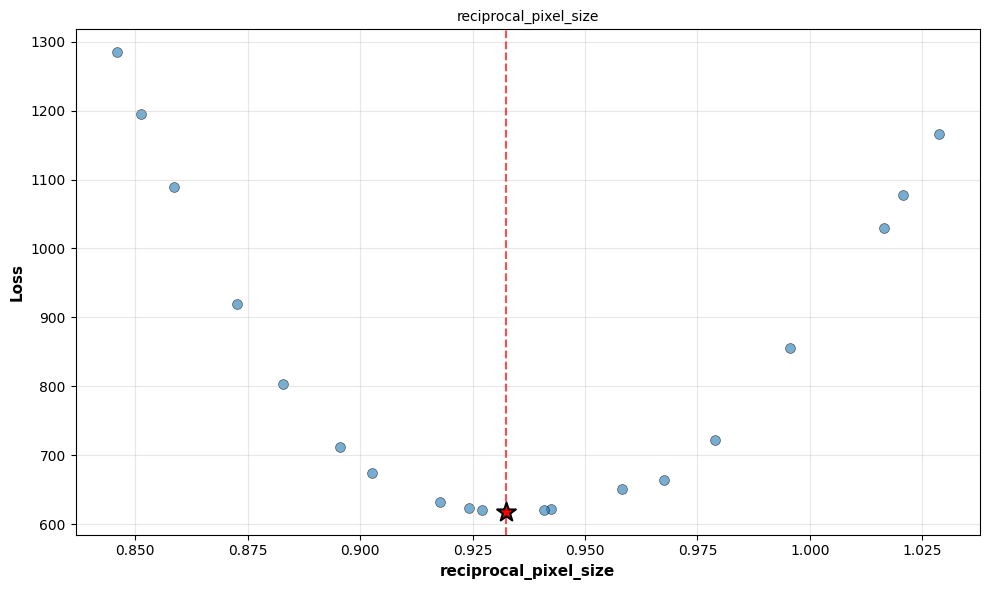

In [23]:
from functools import partial

from quantem.diffractive_imaging.dataset_models import PtychographyDatasetRaster
from quantem.diffractive_imaging.optimize_hyperparameters import (
    OptimizationParameter,
    OptimizePtychography,
)

def make_pdset(dset, reciprocal_pixel_size):
    trial_dset = dc_crop.copy()
    trial_dset.sampling[-2:] = [reciprocal_pixel_size, reciprocal_pixel_size]
    return PtychographyDatasetRaster.from_dataset4dstem(trial_dset, verbose = False,)

constructors = {
    "ptychography_class": PtychoLite.from_dataset,
}

base_kwargs = {
    "init": {
        "device": "gpu",
        "num_slices": 1,
        "obj_type": "pure_phase",
        "num_probes": 1,
        "energy": 300e3,
        "semiangle_cutoff": probe_semiangle,
        "defocus": direct_ptycho.aberration_coefs['C10']
    },
    "reconstruct": {
        "num_iters": 5,
        "batch_size": 128,
    },
}

optimizer = OptimizePtychography.from_constructors(
    constructors=constructors,
    base_kwargs=base_kwargs,
    dataset_constructor=partial(make_pdset, dset=dc_crop),
    dataset_kwargs={
        "reciprocal_pixel_size": OptimizationParameter(low=sampling_inital * 0.9 , high=sampling_inital * 1.1 ),
    },
    dataset_preprocess_kwargs={
        "com_fit_function": "constant",
        "plot_rotation": False,
        "plot_com": False,
        "probe_energy": 300e3,
        "force_com_rotation":-169,
        "force_com_transpose": False,
    },
    reconstruction_class="ptycholite",
    n_trials=20,
    direction="minimize",
    verbose=False,
)

optimizer.optimize().visualize()